# Solar error generalization script

In [21]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde, norm, multivariate_normal
from scipy.special import ndtr
from scipy import interpolate

plt.style.use('default')
plt.rcParams.update({
    'font.size': 13,
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif', 'Liberation Serif', 'serif'],
    'legend.fontsize': 13,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'mathtext.fontset': 'stix',
})

## 1. Data loading and preprocessing

In [22]:
print("=== 1. Data loading and preprocessing ===")

df = pd.read_csv('data/ods032.csv', sep=';')
print(f"Raw data rows: {len(df)}")

df['Datetime'] = pd.to_datetime(df['Datetime'], utc=True)

measured = df['Measured & Upscaled'].values
forecast = df['Most recent forecast'].values

=== 1. Data loading and preprocessing ===
Raw data rows: 11712


In [23]:
mask = (measured != 0) | (forecast != 0)
measured_day = measured[mask]
forecast_day = forecast[mask]

print(f"Rows after filtering night: {len(measured_day)}")

Rows after filtering night: 5002


## 2. Compute forecast error

In [24]:
print("\n=== 2. Compute forecast error ===")

error = measured_day - forecast_day

error_norm = error / np.std(measured_day)

print(f"Error statistics:")
print(f"  mean: {np.mean(error_norm):.4f}")
print(f"  std: {np.std(error_norm):.4f}")
print(f"  min: {np.min(error_norm):.4f}")
print(f"  max: {np.max(error_norm):.4f}")


=== 2. Compute forecast error ===
Error statistics:
  mean: -0.0123
  std: 0.2345
  min: -1.5892
  max: 1.3194


## 3. Reshape to time-series structure

In [25]:
print("\n=== 3. Reshape to time-series structure ===")

n_timepoints = 48
n_days = len(error_norm) // n_timepoints

error_norm = error_norm[:n_days * n_timepoints]

error_matrix = error_norm.reshape(n_days, n_timepoints)

print(f"Error matrix shape: {error_matrix.shape}")
print(f"  periods: {n_days}")
print(f"  timepoints per period: {n_timepoints}")
print(f"  note: these 48 points are all generating periods, night zeros filtered")


=== 3. Reshape to time-series structure ===
Error matrix shape: (104, 48)
  periods: 104
  timepoints per period: 48
  note: these 48 points are all generating periods, night zeros filtered


## 4. Compute temporal correlation

In [26]:
print("\n=== 4. Compute temporal correlation ===")

temp_corr = np.corrcoef(error_matrix, rowvar=False)
print(f"Temporal correlation matrix shape: {temp_corr.shape}")


=== 4. Compute temporal correlation ===
Temporal correlation matrix shape: (48, 48)


Temporal correlation heatmap saved: solar_error_gen_figure/solar_error_temporal_correlation.pdf


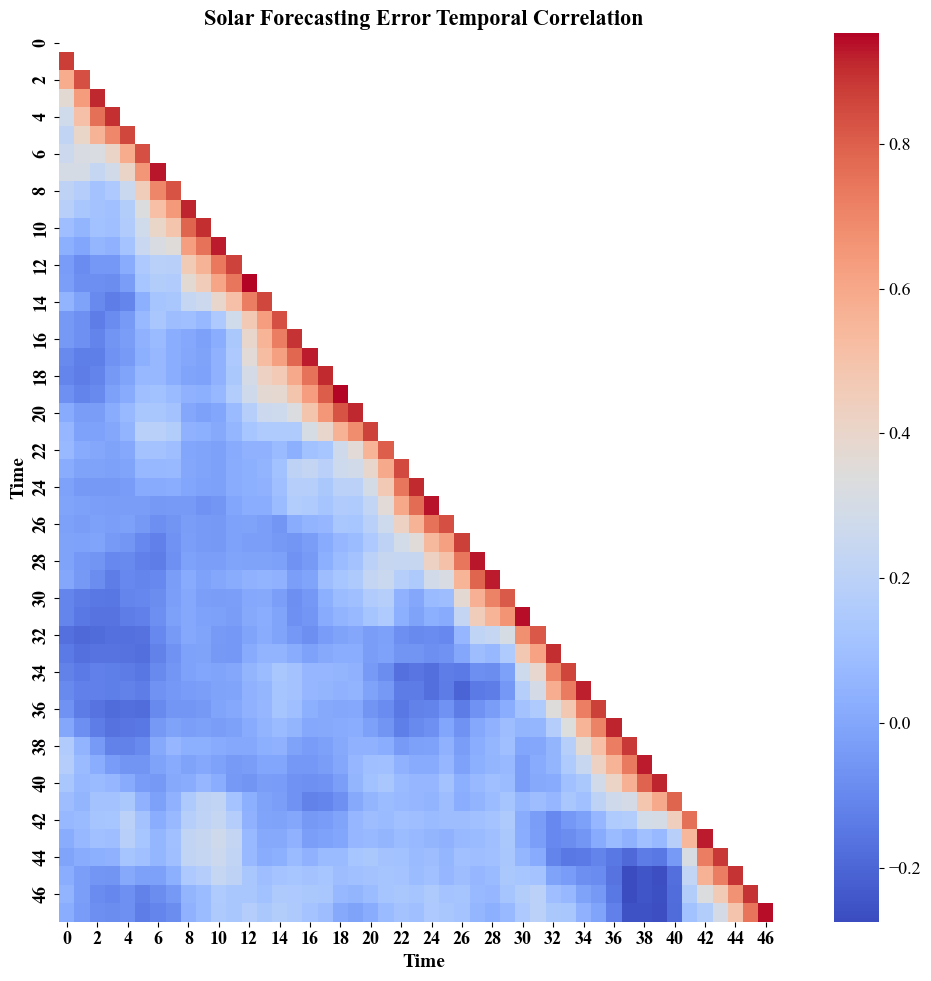

In [27]:
fig, ax = plt.subplots(figsize=(10, 10))
mask_upper = np.triu(np.ones_like(temp_corr, dtype=bool))
sns.heatmap(temp_corr, annot=False, fmt=".2f", mask=mask_upper, cmap='coolwarm', ax=ax)
ax.set_title('Solar Forecasting Error Temporal Correlation', fontsize=16, fontweight='bold')
ax.set_xlabel('Time', fontsize=14, fontweight='bold')
ax.set_ylabel('Time', fontsize=14, fontweight='bold')
fig.canvas.draw()
ax.tick_params(axis='both', which='major', labelsize=13)
plt.setp(ax.get_xticklabels(), fontweight='bold')
plt.setp(ax.get_yticklabels(), fontweight='bold')
plt.tight_layout()
os.makedirs('solar_error_gen_figure', exist_ok=True)
plt.savefig('solar_error_gen_figure/solar_error_temporal_correlation.pdf', dpi=300, bbox_inches='tight')
print("Temporal correlation heatmap saved: solar_error_gen_figure/solar_error_temporal_correlation.pdf")
plt.show()

## 5. Fit marginal distribution with KDE

In [28]:
print("\n=== 5. Fit marginal distribution with KDE ===")

marginal_error = error_matrix.flatten()

kde = gaussian_kde(marginal_error)

x = np.linspace(np.min(marginal_error), np.max(marginal_error), 100)
kde_pdf = kde.pdf(x)

mu, std = np.mean(marginal_error), np.std(marginal_error)
p = norm.pdf(x, mu, std)


=== 5. Fit marginal distribution with KDE ===


Marginal distribution figure saved: solar_error_gen_figure/solar_error_marginal_distribution.pdf


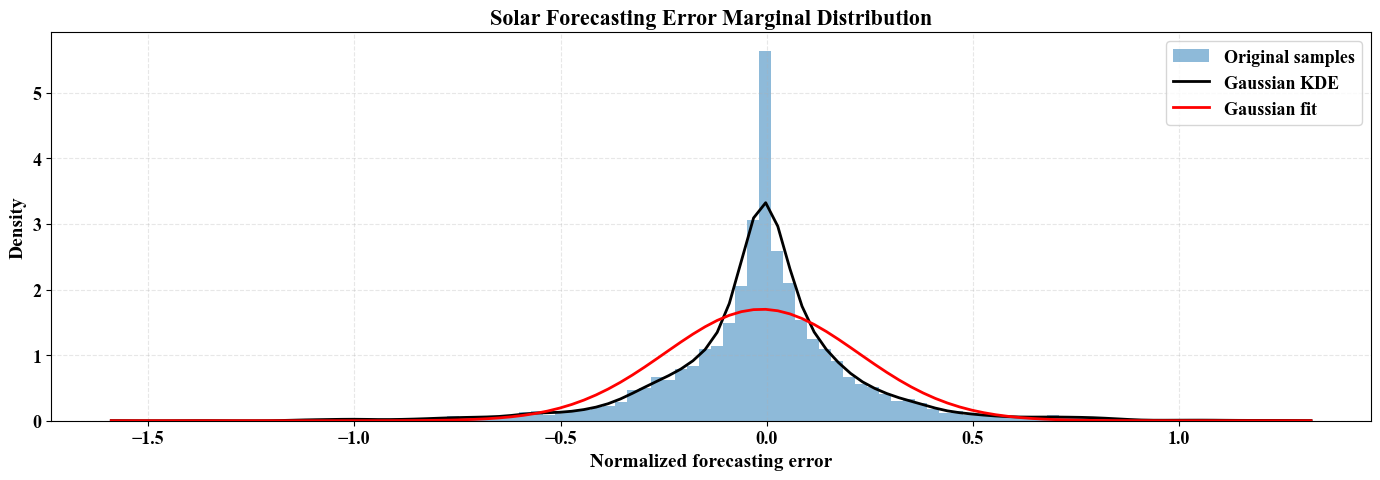

In [29]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.hist(marginal_error, bins=100, alpha=0.5, label='Original samples', density=True)
ax.plot(x, kde_pdf, 'k', linewidth=2, label='Gaussian KDE')
ax.plot(x, p, 'r', linewidth=2, label='Gaussian fit')
ax.set_xlabel('Normalized forecasting error', fontsize=14, fontweight='bold')
ax.set_ylabel('Density', fontsize=14, fontweight='bold')
ax.legend(prop={'weight': 'bold', 'size': 13})
ax.set_title('Solar Forecasting Error Marginal Distribution', fontsize=16, fontweight='bold')
fig.canvas.draw()
ax.tick_params(axis='both', which='major', labelsize=13)
plt.setp(ax.get_xticklabels(), fontweight='bold')
plt.setp(ax.get_yticklabels(), fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
os.makedirs('solar_error_gen_figure', exist_ok=True)
plt.savefig('solar_error_gen_figure/solar_error_marginal_distribution.pdf', dpi=300, bbox_inches='tight')
print("Marginal distribution figure saved: solar_error_gen_figure/solar_error_marginal_distribution.pdf")
plt.show()

## 6. Generate temporally correlated samples via Copula

In [30]:
print("\n=== 6. Generate temporally correlated samples via Copula ===")

n_scenario = 200000
print(f"Number of scenarios: {n_scenario}")


=== 6. Generate temporally correlated samples via Copula ===
Number of scenarios: 200000


In [31]:
mvnorm = multivariate_normal(mean=np.zeros(temp_corr.shape[0]), cov=temp_corr)
samples_gaussian = mvnorm.rvs(size=n_scenario, random_state=0)
print(f"Multivariate normal samples shape: {samples_gaussian.shape}")

Multivariate normal samples shape: (200000, 48)


In [32]:
norm_dist = norm()
samples_uniform = norm_dist.cdf(samples_gaussian)
print(f"Uniform samples shape: {samples_uniform.shape}")

Uniform samples shape: (200000, 48)


In [33]:
print("Computing KDE CDF (batched to save memory)...")

stdev = np.sqrt(kde.covariance)[0, 0]
xmax = np.max(marginal_error)
xmin = np.min(marginal_error)
minmax_dist = xmax - xmin

xx = np.linspace(xmin - 0.*minmax_dist, xmax + 0.*minmax_dist, 5000)

n_resample = 50000
n = kde.resample(n_resample, seed=0).flatten()

batch_size = 1000
kde_cdf = np.zeros(len(xx))
for i in range(0, len(xx), batch_size):
    batch_end = min(i + batch_size, len(xx))
    xx_batch = xx[i:batch_end]
    kde_cdf[i:batch_end] = ndtr(np.subtract.outer(xx_batch, n)/stdev).mean(axis=1)
    if (i // batch_size) % 5 == 0:
        print(f"  progress: {batch_end}/{len(xx)}")

print("KDE CDF computation done")

Computing KDE CDF (batched to save memory)...
  progress: 1000/5000
KDE CDF computation done


In [34]:
kde_cdf_inv_func = interpolate.interp1d(kde_cdf, xx, kind='cubic', 
                                        bounds_error=False, fill_value='extrapolate')

In [35]:
samples_kde_corr = np.vstack([kde_cdf_inv_func(samples_uniform[:, i]) 
                               for i in range(temp_corr.shape[0])]).T
print(f"Final temporally correlated samples shape: {samples_kde_corr.shape}")

Final temporally correlated samples shape: (200000, 48)


## 7. Validate generated samples


=== 7. Validate generated samples ===
Sample comparison figure saved: solar_error_gen_figure/solar_error_comparison.pdf


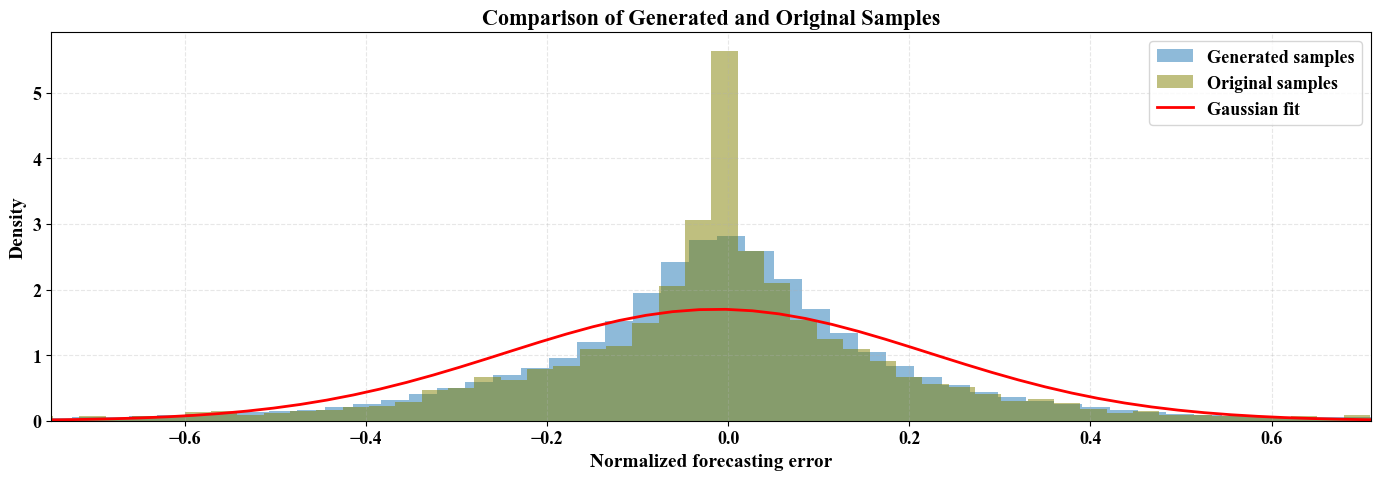

In [36]:
print("\n=== 7. Validate generated samples ===")

fig, ax = plt.subplots(figsize=(14, 5))
ax.hist(samples_kde_corr.flatten(), bins=100, alpha=0.5,
        label='Generated samples', density=True)
ax.hist(marginal_error, bins=100, alpha=0.5,
        label='Original samples', density=True, color='olive')
ax.plot(x, p, 'r', linewidth=2, label='Gaussian fit')
ax.set_xlim(np.percentile(marginal_error, 1), np.percentile(marginal_error, 99))
ax.set_xlabel('Normalized forecasting error', fontsize=14, fontweight='bold')
ax.set_ylabel('Density', fontsize=14, fontweight='bold')
ax.legend(prop={'weight': 'bold', 'size': 13})
ax.set_title('Comparison of Generated and Original Samples', fontsize=16, fontweight='bold')
fig.canvas.draw()
ax.tick_params(axis='both', which='major', labelsize=13)
plt.setp(ax.get_xticklabels(), fontweight='bold')
plt.setp(ax.get_yticklabels(), fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
os.makedirs('solar_error_gen_figure', exist_ok=True)
plt.savefig('solar_error_gen_figure/solar_error_comparison.pdf', dpi=300, bbox_inches='tight')
print("Sample comparison figure saved: solar_error_gen_figure/solar_error_comparison.pdf")
plt.show()

Temporal correlation comparison figure saved: solar_error_gen_figure/solar_error_temporal_correlation_comparison.pdf


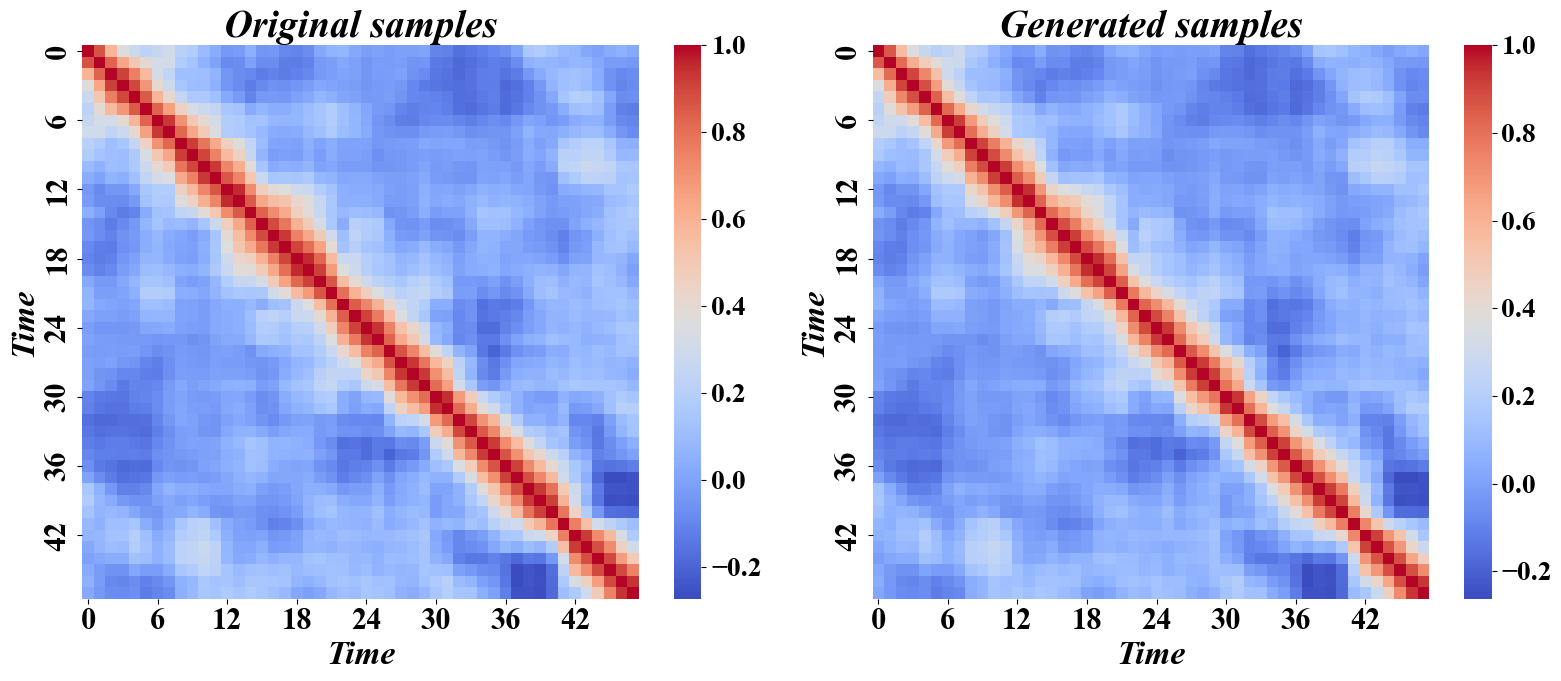

In [37]:
temp_corr_gen = np.corrcoef(samples_kde_corr, rowvar=False)
tick_labels = np.arange(0, temp_corr.shape[0], 6)
tick_positions = tick_labels + 0.5

fig, axs = plt.subplots(1, 2, figsize=(16, 7))
axs[0].set_title('Original samples', fontsize=28, fontweight='bold', fontstyle='italic')
sns.heatmap(temp_corr, annot=False, fmt=".2f", mask=None, ax=axs[0], cmap='coolwarm')
axs[1].set_title('Generated samples', fontsize=28, fontweight='bold', fontstyle='italic')
sns.heatmap(temp_corr_gen, annot=False, fmt=".2f", mask=None, ax=axs[1], cmap='coolwarm')

for ax in axs:
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_labels)
    ax.set_yticks(tick_positions)
    ax.set_yticklabels(tick_labels)
    ax.set_xlabel('Time', fontsize=24, fontweight='bold', fontstyle='italic')
    ax.set_ylabel('Time', fontsize=24, fontweight='bold', fontstyle='italic')
    fig.canvas.draw()
    ax.tick_params(axis='both', which='major', labelsize=22)
    plt.setp(ax.get_xticklabels(), fontweight='bold')
    plt.setp(ax.get_yticklabels(), fontweight='bold')
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=20)
    plt.setp(cbar.ax.get_yticklabels(), fontweight='bold')

plt.tight_layout()
os.makedirs('solar_error_gen_figure', exist_ok=True)
plt.savefig('solar_error_gen_figure/solar_error_temporal_correlation_comparison.pdf', dpi=300, bbox_inches='tight')
print("Temporal correlation comparison figure saved: solar_error_gen_figure/solar_error_temporal_correlation_comparison.pdf")
plt.show()

## 8. Save results

In [38]:
print("\n=== 8. Save results ===")

np.save('data/solar_temporal_correlated_error_samples.npy', samples_kde_corr)
print(f"Error samples saved: data/solar_temporal_correlated_error_samples.npy")
print(f"  shape: {samples_kde_corr.shape}")


=== 8. Save results ===
Error samples saved: data/solar_temporal_correlated_error_samples.npy
  shape: (200000, 48)


In [39]:
solar_forecast_prototype = forecast_day[:48]

np.save('data/solar_forecast_prototype.npy', solar_forecast_prototype)
print(f"Solar forecast prototype saved: data/solar_forecast_prototype.npy")
print(f"  shape: {solar_forecast_prototype.shape}")
print(f"  note: these 48 points correspond to daytime generating-period forecasts")

Solar forecast prototype saved: data/solar_forecast_prototype.npy
  shape: (48,)
  note: these 48 points correspond to daytime generating-period forecasts


## Summary and usage notes

In [40]:
print("\n=== Solar error generalization done ===")
print(f"Generated {n_scenario} solar error scenarios")
print(f"Each scenario has {n_timepoints} timepoints (all daytime generating periods)")
print("\n=== Usage notes ===")
print("When building full 24-hour scenarios:")
print("  1. Night hours (19-4): set to 0")
print("  2. Day hours (5-18): use forecast + error samples * forecast std")
print("  3. Ensure final scenario values are non-negative (clip(0, None))")


=== Solar error generalization done ===
Generated 200000 solar error scenarios
Each scenario has 48 timepoints (all daytime generating periods)

=== Usage notes ===
When building full 24-hour scenarios:
  1. Night hours (19-4): set to 0
  2. Day hours (5-18): use forecast + error samples * forecast std
  3. Ensure final scenario values are non-negative (clip(0, None))
